# 03 – Exploratory Data Analysis

**Goal:** Visualize the main SQL findings and explore the variables for the default model.

**Data:** `vw_loans` (PostgreSQL view), joined with `dim_date` and `dim_state`.
Charts are saved to `images/` for the README.

In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine

load_dotenv("../.env")
engine = create_engine(os.getenv("DATABASE_URL"))

IMAGES_DIR = Path("../images")
IMAGES_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110


def save_fig(fig, name):
    """Save a chart to the images folder for the README."""
    fig.savefig(IMAGES_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

## 2. Load data
All completed loans are loaded with the `is_mature` flag, so the same table can be used for both views.
Year comes from `dim_date` and region from `dim_state`, the same model as in SQL.

In [4]:
LOANS_QUERY = """
SELECT
    l.*,
    d.year,
    d.year_quarter,
    s.region
FROM vw_loans AS l
JOIN dim_date  AS d ON l.issue_date = d.month_date
JOIN dim_state AS s ON l.addr_state = s.state_code
"""
loans = pd.read_sql(LOANS_QUERY, engine, parse_dates=["issue_date"])

print(loans.shape)
print(f"Mature loans: {loans['is_mature'].sum():,}")
loans.dtypes

(1347698, 24)
Mature loans: 676,296


id                         int64
issue_date         datetime64[s]
addr_state                   str
term_months                int64
grade                        str
sub_grade                    str
grade_group                  str
purpose                      str
home_ownership               str
loan_amnt                float64
int_rate                 float64
fico_avg                 float64
fico_band                    str
fico_band_order            int64
dti                      float64
dti_band                     str
dti_band_order             int64
is_default                 int64
net_loss                 float64
net_return               float64
is_mature                  int64
year                       int64
year_quarter                 str
region                       str
dtype: object

## 3. Selection bias
Loans issued after 2015 look riskier when all completed loans are used, because most of them were still open
when the data ends. Mature loans remove this effect (see Q2 and Q2b).

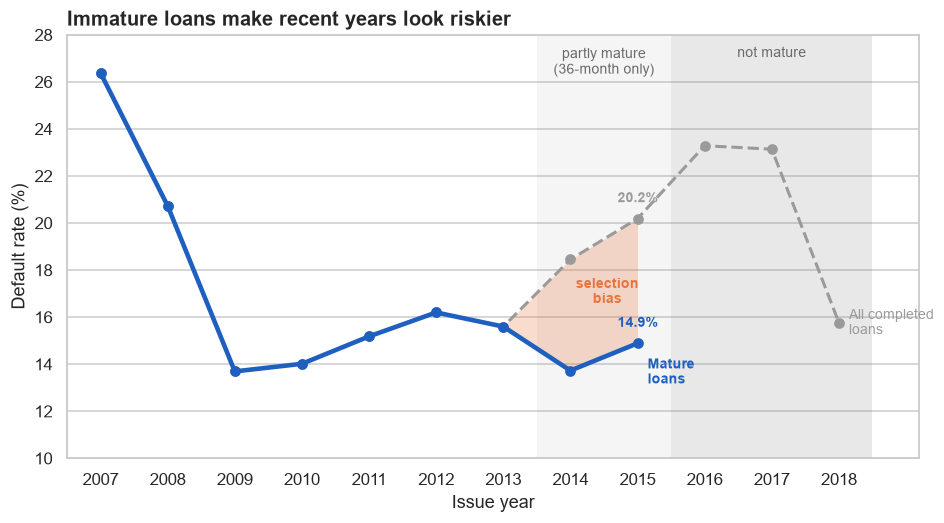

In [8]:
yearly = (
    loans.groupby("year")
    .agg(all_loans=("is_default", "mean"))
    .join(
        loans[loans["is_mature"] == 1]
        .groupby("year")
        .agg(mature_loans=("is_default", "mean"))
    )
    * 100
)

ALL_COLOR = "#9a9a9a"
MATURE_COLOR = "#1f5fbf"
GAP_COLOR = "#e8743b"

fig, ax = plt.subplots(figsize=(10, 5))

# Background: maturity periods
ax.axvspan(2013.5, 2015.5, color="grey", alpha=0.08, lw=0)
ax.axvspan(2015.5, 2018.5, color="grey", alpha=0.18, lw=0)
ax.text(2014.5, 27.5, "partly mature\n(36-month only)", ha="center", va="top", fontsize=9, color="dimgrey")
ax.text(2017, 27.5, "not mature", ha="center", va="top", fontsize=9, color="dimgrey")

# Gap between the two lines = selection bias
gap = yearly.loc[2013:2015]
ax.fill_between(gap.index, gap["mature_loans"], gap["all_loans"], color=GAP_COLOR, alpha=0.25, lw=0)
ax.text(2014.55, 16.6, "selection\nbias", ha="center", fontsize=9, color=GAP_COLOR, fontweight="bold")

# Lines
ax.plot(yearly.index, yearly["all_loans"], color=ALL_COLOR, linestyle="--", marker="o", lw=2)
ax.plot(yearly.index, yearly["mature_loans"], color=MATURE_COLOR, marker="o", lw=3)

# Direct labels instead of a legend
ax.text(2018.15, yearly.loc[2018, "all_loans"], "All completed\nloans", va="center", fontsize=9, color=ALL_COLOR)
ax.text(2015.15, yearly.loc[2015, "mature_loans"] - 0.6, "Mature\nloans", va="top", fontsize=9,
        color=MATURE_COLOR, fontweight="bold")

# Values for 2015
for column, color, offset in [("all_loans", ALL_COLOR, 0.7), ("mature_loans", MATURE_COLOR, 0.7)]:
    value = yearly.loc[2015, column]
    ax.text(2015, value + offset, f"{value:.1f}%", ha="center", fontsize=9, color=color, fontweight="bold")

ax.set_title("Immature loans make recent years look riskier", loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("Issue year")
ax.set_ylabel("Default rate (%)")
ax.set_xticks(yearly.index)
ax.set_xlim(2006.5, 2019.2)
ax.set_ylim(10, 28)
ax.grid(axis="x", visible=False)

save_fig(fig, "01_selection_bias")
plt.show()